# CE 477 – Data Science: Assignment #2 (Part 1: Classification)

**Institution:** Izmir University of Economics  
**Department:** Department of Computer Engineering  
**Dataset:** AFAD Seismic Activity Catalog (Preprocessed Dataset, $N = 153,439$)

---

## 1. Problem Formulation and Target Attribute Selection

In accordance with **Assignment #2 – Task 1 (Classification)**, this notebook implements an end-to-end supervised classification pipeline on the preprocessed AFAD earthquake catalog (`data/afad_earthquake_data_preprocessed.csv`):

1. **Discrete Target Attribute (`target_class`):** We utilize the discretized earthquake severity attribute derived from continuous magnitude measurements (`magnitude_class`), consolidated into three seismologically meaningful and statistically well-supported severity tiers:
   - **Class 0 – `Micro (<3.0)`:** Background micro-seismicity ($102,656$ events, $66.90\%$).
   - **Class 1 – `Minor (3.0-3.9)`:** Felt local minor earthquakes ($45,983$ events, $29.97\%$).
   - **Class 2 – `Light+ (>=4.0)`:** Significant and potentially damaging seismic events combining Light ($4.0$–$4.9$), Moderate ($5.0$–$5.9$), and Strong+ ($\ge 6.0$) shocks ($4,800$ events, $3.13\%$).
2. **Strict Data Leakage Prevention:** All direct magnitude representations (`magnitude`, `magnitude_norm`, `magnitude_std`, `is_major`) and global full-dataset projections (`PCA1`, `PCA2`, `PCA3`) are strictly excluded from the predictor matrix $X$.
3. **Data Partitioning:** Stratified **60% Training** ($92,063$ rows), **20% Validation** ($30,688$ rows), and **20% Testing** ($30,688$ rows) splits ensure identical class proportions across all partitions while preventing feature engineering or scaling leakage.
4. **Classification Algorithms Evaluated:**
   - **Decision Tree Classifier** *(Mandatory white-box hierarchical rule learner)*
   - **Random Forest Classifier** *(Bagging tree ensemble)*
   - **Logistic Regression** *(Multinomial linear probabilistic baseline)*
   - **Gradient Boosting Classifier** *(Histogram-based boosted decision trees)*

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 300
os.makedirs("../figures", exist_ok=True)
print("Environment initialized successfully.")

Environment initialized successfully.

### Analysis of Environment and Tooling
The core scientific computing stack (`numpy`, `pandas`, `scikit-learn`, `matplotlib`, and `seaborn`) is configured with deterministic random seeds (`random_state=42`) to guarantee full reproducibility across training, validation, and testing splits.

In [2]:
# Load preprocessed AFAD earthquake catalog
df = pd.read_csv("../data/afad_earthquake_data_preprocessed.csv")
df = df.loc[:, ~df.columns.duplicated()]
print(f"Loaded dataset shape: {df.shape}")

# Parse datetime for cyclical temporal feature extraction
df["datetime"] = pd.to_datetime(df["datetime"], errors="coerce")
df["month"] = df["datetime"].dt.month.fillna(6).astype(int)
df["hour"] = df["datetime"].dt.hour.fillna(12).astype(int)
df["month_sin"] = np.sin(2 * np.pi * df["month"] / 12.0)
df["month_cos"] = np.cos(2 * np.pi * df["month"] / 12.0)
df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24.0)
df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24.0)

# Map discretized magnitude_class into 3 ordinal severity classes
class_mapping = {
    "Micro (<3.0)": 0,
    "Minor (3.0-3.9)": 1,
    "Light (4.0-4.9)": 2,
    "Moderate (5.0-5.9)": 2,
    "Strong+ (>=6.0)": 2,
}
class_names = ["Micro (<3.0)", "Minor (3.0-3.9)", "Light+ (>=4.0)"]
df["target_class"] = df["magnitude_class"].map(class_mapping)
print(f"Missing target values after mapping: {df['target_class'].isna().sum()}\n")

print("=== Target Attribute Distribution (Discretized Magnitude Severity) ===")
for idx, name in enumerate(class_names):
    cnt = int((df["target_class"] == idx).sum())
    pct = 100.0 * cnt / len(df)
    print(f"  Class {idx} | {name:<15} : {cnt:>8,} events ({pct:>5.2f}%)")

Loaded dataset shape: (153439, 36)
Missing target values after mapping: 0

=== Target Attribute Distribution (Discretized Magnitude Severity) ===
  Class 0 | Micro (<3.0)    :  102,656 events (66.90%)
  Class 1 | Minor (3.0-3.9) :   45,983 events (29.97%)
  Class 2 | Light+ (>=4.0)  :    4,800 events ( 3.13%)

### Analysis of Target Attribute Distribution
The target attribute exhibits the power-law frequency distribution governed by the **Gutenberg–Richter law** ($\log_{10} N = a - bM$), where earthquake frequency decays exponentially with increasing magnitude:
- **Micro earthquakes ($<3.0$)** account for **$66.90\%$** ($102,656$ records) of the catalog.
- **Minor earthquakes ($3.0$–$3.9$)** constitute **$29.97\%$** ($45,983$ records).
- **Light and stronger events ($\ge 4.0$)** represent **$3.13\%$** ($4,800$ records).

Consolidating events with $M \ge 4.0$ into `Light+ (>=4.0)` yields $960$ test samples and $960$ validation samples in the 20% partitions, ensuring statistically low-variance estimates of Precision, Recall, and F1-score while preserving the natural multi-class imbalance challenge of real-world seismic catalogs.

In [3]:
# Select strictly non-leaking spatial, temporal, and instrumentation features
base_features = [
    "latitude", "longitude", "depth", "rms", "year",
    "month_sin", "month_cos", "hour_sin", "hour_cos",
    "type_ML", "type_Md", "type_Ml", "type_Mw", "type_Other",
    "province"
]

X_raw = df[base_features].copy()
y = df["target_class"].astype(int).values

# Step 1: 60% Training vs 40% Temporary split (Stratified)
X_train_raw, X_temp_raw, y_train, y_temp = train_test_split(
    X_raw, y, test_size=0.40, stratify=y, random_state=42
)

# Step 2: Split 40% Temporary equally into 20% Validation and 20% Testing (Stratified)
X_val_raw, X_test_raw, y_val, y_test = train_test_split(
    X_temp_raw, y_temp, test_size=0.50, stratify=y_temp, random_state=42
)

# Step 3: Fit spatial province statistics strictly on the 60% Training set
prov_freq = X_train_raw["province"].value_counts(normalize=True).to_dict()
train_tmp = X_train_raw.copy()
train_tmp["target"] = y_train
prov_target_rate = train_tmp.groupby("province")["target"].mean().to_dict()
global_target_mean = float(np.mean(y_train))

def engineer_features(part_df):
    out = part_df.drop(columns=["province"]).copy()
    out["province_freq"] = part_df["province"].map(prov_freq).fillna(0.0)
    out["province_seismic_index"] = part_df["province"].map(prov_target_rate).fillna(global_target_mean)
    out["log_depth"] = np.log1p(np.maximum(0.0, out["depth"]))
    out["log_rms"] = np.log1p(np.maximum(0.0, out["rms"]))
    out["lat_lon_interaction"] = out["latitude"] * out["longitude"]
    return out

X_train_fe = engineer_features(X_train_raw)
X_val_fe = engineer_features(X_val_raw)
X_test_fe = engineer_features(X_test_raw)
feature_names = list(X_train_fe.columns)

# Step 4: Fit StandardScaler strictly on Training continuous attributes
continuous_cols = [
    "latitude", "longitude", "depth", "rms", "year",
    "month_sin", "month_cos", "hour_sin", "hour_cos",
    "province_freq", "province_seismic_index",
    "log_depth", "log_rms", "lat_lon_interaction"
]
scaler = StandardScaler()
X_train_scaled = X_train_fe.copy()
X_val_scaled = X_val_fe.copy()
X_test_scaled = X_test_fe.copy()

X_train_scaled[continuous_cols] = scaler.fit_transform(X_train_fe[continuous_cols])
X_val_scaled[continuous_cols] = scaler.transform(X_val_fe[continuous_cols])
X_test_scaled[continuous_cols] = scaler.transform(X_test_fe[continuous_cols])

print("=== Stratified 60% / 20% / 20% Data Split Summary ===")
print(f"  Training Set   (60%): {len(X_train_fe):,} rows | Class counts: {np.bincount(y_train).tolist()}")
print(f"  Validation Set (20%): {len(X_val_fe):,} rows | Class counts: {np.bincount(y_val).tolist()}")
print(f"  Testing Set    (20%): {len(X_test_fe):,} rows | Class counts: {np.bincount(y_test).tolist()}\n")
print(f"Total leakage-free predictor features ({len(feature_names)}):\n  {feature_names}")

=== Stratified 60% / 20% / 20% Data Split Summary ===
  Training Set   (60%): 92,063 rows | Class counts: [61593, 27590, 2880]
  Validation Set (20%): 30,688 rows | Class counts: [20531, 9197, 960]
  Testing Set    (20%): 30,688 rows | Class counts: [20532, 9196, 960]

Total leakage-free predictor features (19):
  ['latitude', 'longitude', 'depth', 'rms', 'year', 'month_sin', 'month_cos', 'hour_sin', 'hour_cos', 'type_ML', 'type_Md', 'type_Ml', 'type_Mw', 'type_Other', 'province_freq', 'province_seismic_index', 'log_depth', 'log_rms', 'lat_lon_interaction']

### Analysis of Stratified Partitioning and Feature Engineering
1. **Exact 60% / 20% / 20% Proportions:** Each split preserves the exact class distribution ($66.90\%$ `Micro`, $29.97\%$ `Minor`, and $3.13\%$ `Light+`).
2. **Strict Separation of Training Statistics:** Both regional encoders (`province_freq` and `province_seismic_index`) and `StandardScaler` parameters ($\mu, \sigma$) are estimated exclusively on the $92,063$ training observations and subsequently applied to the validation and testing sets. This eliminates any information leakage from validation or test samples into model training.
3. **Domain-Specific Non-Linear Features:** Logarithmic transforms (`log_depth`, `log_rms`) compress right-skewed hypocenter depth and waveform root-mean-square travel-time residual distributions, helping linear models (`LogisticRegression`) as well as tree splits.

In [4]:
# Hyperparameter tuning for Decision Tree on the 20% Validation Set
depths_to_try = [4, 6, 8, 10, 12, 14, 16, 20]
dt_tuning_records = []
best_dt_depth = None
best_dt_val_f1 = -1.0

print("=== Decision Tree Validation Set Hyperparameter Tuning ===")
print("  max_depth | Train Weighted F1 | Val Accuracy | Val Weighted F1 | Val Macro F1")
print("  -----------------------------------------------------------------------------")

for d in depths_to_try:
    dt_cand = DecisionTreeClassifier(max_depth=d, min_samples_leaf=25, criterion="gini", random_state=42)
    dt_cand.fit(X_train_fe, y_train)
    tr_pred = dt_cand.predict(X_train_fe)
    va_pred = dt_cand.predict(X_val_fe)
    tr_wf1 = f1_score(y_train, tr_pred, average="weighted")
    va_acc = accuracy_score(y_val, va_pred)
    va_wf1 = f1_score(y_val, va_pred, average="weighted")
    va_mf1 = f1_score(y_val, va_pred, average="macro")
    dt_tuning_records.append({
        "max_depth": d,
        "train_weighted_f1": tr_wf1,
        "val_accuracy": va_acc,
        "val_weighted_f1": va_wf1,
        "val_macro_f1": va_mf1,
    })
    print(f"  {d:>9} | {tr_wf1:>17.4f} | {va_acc:>12.4f} | {va_wf1:>15.4f} | {va_mf1:>12.4f}")
    if va_wf1 > best_dt_val_f1:
        best_dt_val_f1 = va_wf1
        best_dt_depth = d

print(f"\nSelected Optimal Decision Tree Depth: max_depth = {best_dt_depth} (Validation Weighted F1 = {best_dt_val_f1:.4f})")

# Train all 4 classification algorithms on the 60% Training Set
models = {
    "Decision Tree": (
        DecisionTreeClassifier(max_depth=best_dt_depth, min_samples_leaf=25, criterion="gini", random_state=42),
        False
    ),
    "Random Forest": (
        RandomForestClassifier(n_estimators=150, max_depth=16, min_samples_leaf=10, n_jobs=-1, random_state=42),
        False
    ),
    "Logistic Regression": (
        LogisticRegression(max_iter=500, C=1.0, random_state=42),
        True
    ),
    "Gradient Boosting": (
        HistGradientBoostingClassifier(max_iter=200, max_depth=10, learning_rate=0.08, min_samples_leaf=25, random_state=42),
        False
    ),
}

trained_models = {}
val_predictions = {}
test_predictions = {}

for name, (clf, use_scaled) in models.items():
    X_tr = X_train_scaled if use_scaled else X_train_fe
    X_va = X_val_scaled if use_scaled else X_val_fe
    X_te = X_test_scaled if use_scaled else X_test_fe
    clf.fit(X_tr, y_train)
    trained_models[name] = clf
    val_predictions[name] = clf.predict(X_va)
    test_predictions[name] = clf.predict(X_te)

print("\nAll 4 classification models trained successfully on the 60% Training Set.")

=== Decision Tree Validation Set Hyperparameter Tuning ===
  max_depth | Train Weighted F1 | Val Accuracy | Val Weighted F1 | Val Macro F1
  -----------------------------------------------------------------------------
          4 |            0.6050 |       0.6969 |          0.6009 |       0.4063
          6 |            0.6896 |       0.7078 |          0.6863 |       0.5297
          8 |            0.7010 |       0.7172 |          0.6939 |       0.5262
         10 |            0.7142 |       0.7266 |          0.6995 |       0.5393
         12 |            0.7269 |       0.7302 |          0.7034 |       0.5471
         14 |            0.7397 |       0.7275 |          0.7065 |       0.5524
         16 |            0.7482 |       0.7268 |          0.7062 |       0.5539
         20 |            0.7629 |       0.7211 |          0.7071 |       0.5573

Selected Optimal Decision Tree Depth: max_depth = 20 (Validation Weighted F1 = 0.7071)

All 4 classification models trained successfully on 

### Analysis of Validation Set Hyperparameter Tuning
The validation curve demonstrates the classic bias–variance trade-off for the **Decision Tree Classifier**:
- At shallow depths (`max_depth=4`), the tree suffers from high bias (underfitting), achieving a Validation Weighted F1 of only **$0.6009$** and Macro F1 of **$0.4063$**.
- Increasing `max_depth` from $6$ to $14$ produces substantial gains in both Weighted F1 ($0.6863 \rightarrow 0.7065$) and Macro F1 ($0.5297 \rightarrow 0.5524$) as the tree captures hierarchical interactions among magnitude scale type (`type_Mw`, `type_ML`), hypocenter `depth`, travel-time residual `rms`, and tectonic coordinates (`latitude`, `longitude`).
- Constraining `min_samples_leaf=25` regularizes the leaf nodes so that even at `max_depth=20` (where Validation Weighted F1 reaches **$0.7071$** and Macro F1 reaches **$0.5573$**), the gap between Training Weighted F1 ($0.7629$) and Validation Weighted F1 ($0.7071$) remains bounded.

=== Learned Decision Tree Top-3 Hierarchy Rules ===
|--- type_Mw <= 0.50
|   |--- depth <= 7.88
|   |   |--- type_Other <= 0.50
|   |   |   |--- depth <= 6.43
|   |   |   |   |--- truncated branch of depth 17
|   |   |   |--- depth >  6.43
|   |   |   |   |--- truncated branch of depth 17
|   |   |--- type_Other >  0.50
|   |   |   |--- longitude <= 26.14
|   |   |   |   |--- truncated branch of depth 4
|   |   |   |--- longitude >  26.14
|   |   |   |   |--- truncated branch of depth 9
|   |--- depth >  7.88
|   |   |--- type_Other <= 0.50
|   |   |   |--- type_ML <= 0.50
|   |   |   |   |--- truncated branch of depth 17
|   |   |   |--- type_ML >  0.50
|   |   |   |   |--- truncated branch of depth 17
|   |   |--- type_Other >  0.50
|   |   |   |--- hour_sin <= 0.79
|   |   |   |   |--- truncated branch of depth 8
|   |   |   |--- hour_sin >  0.79
|   |   |   |   |--- truncated branch of depth 4
|--- type_Mw >  0.50
|   |--- rms <= 0.48
|   |   |--- log_depth <= 2.15
|   |   |   |---

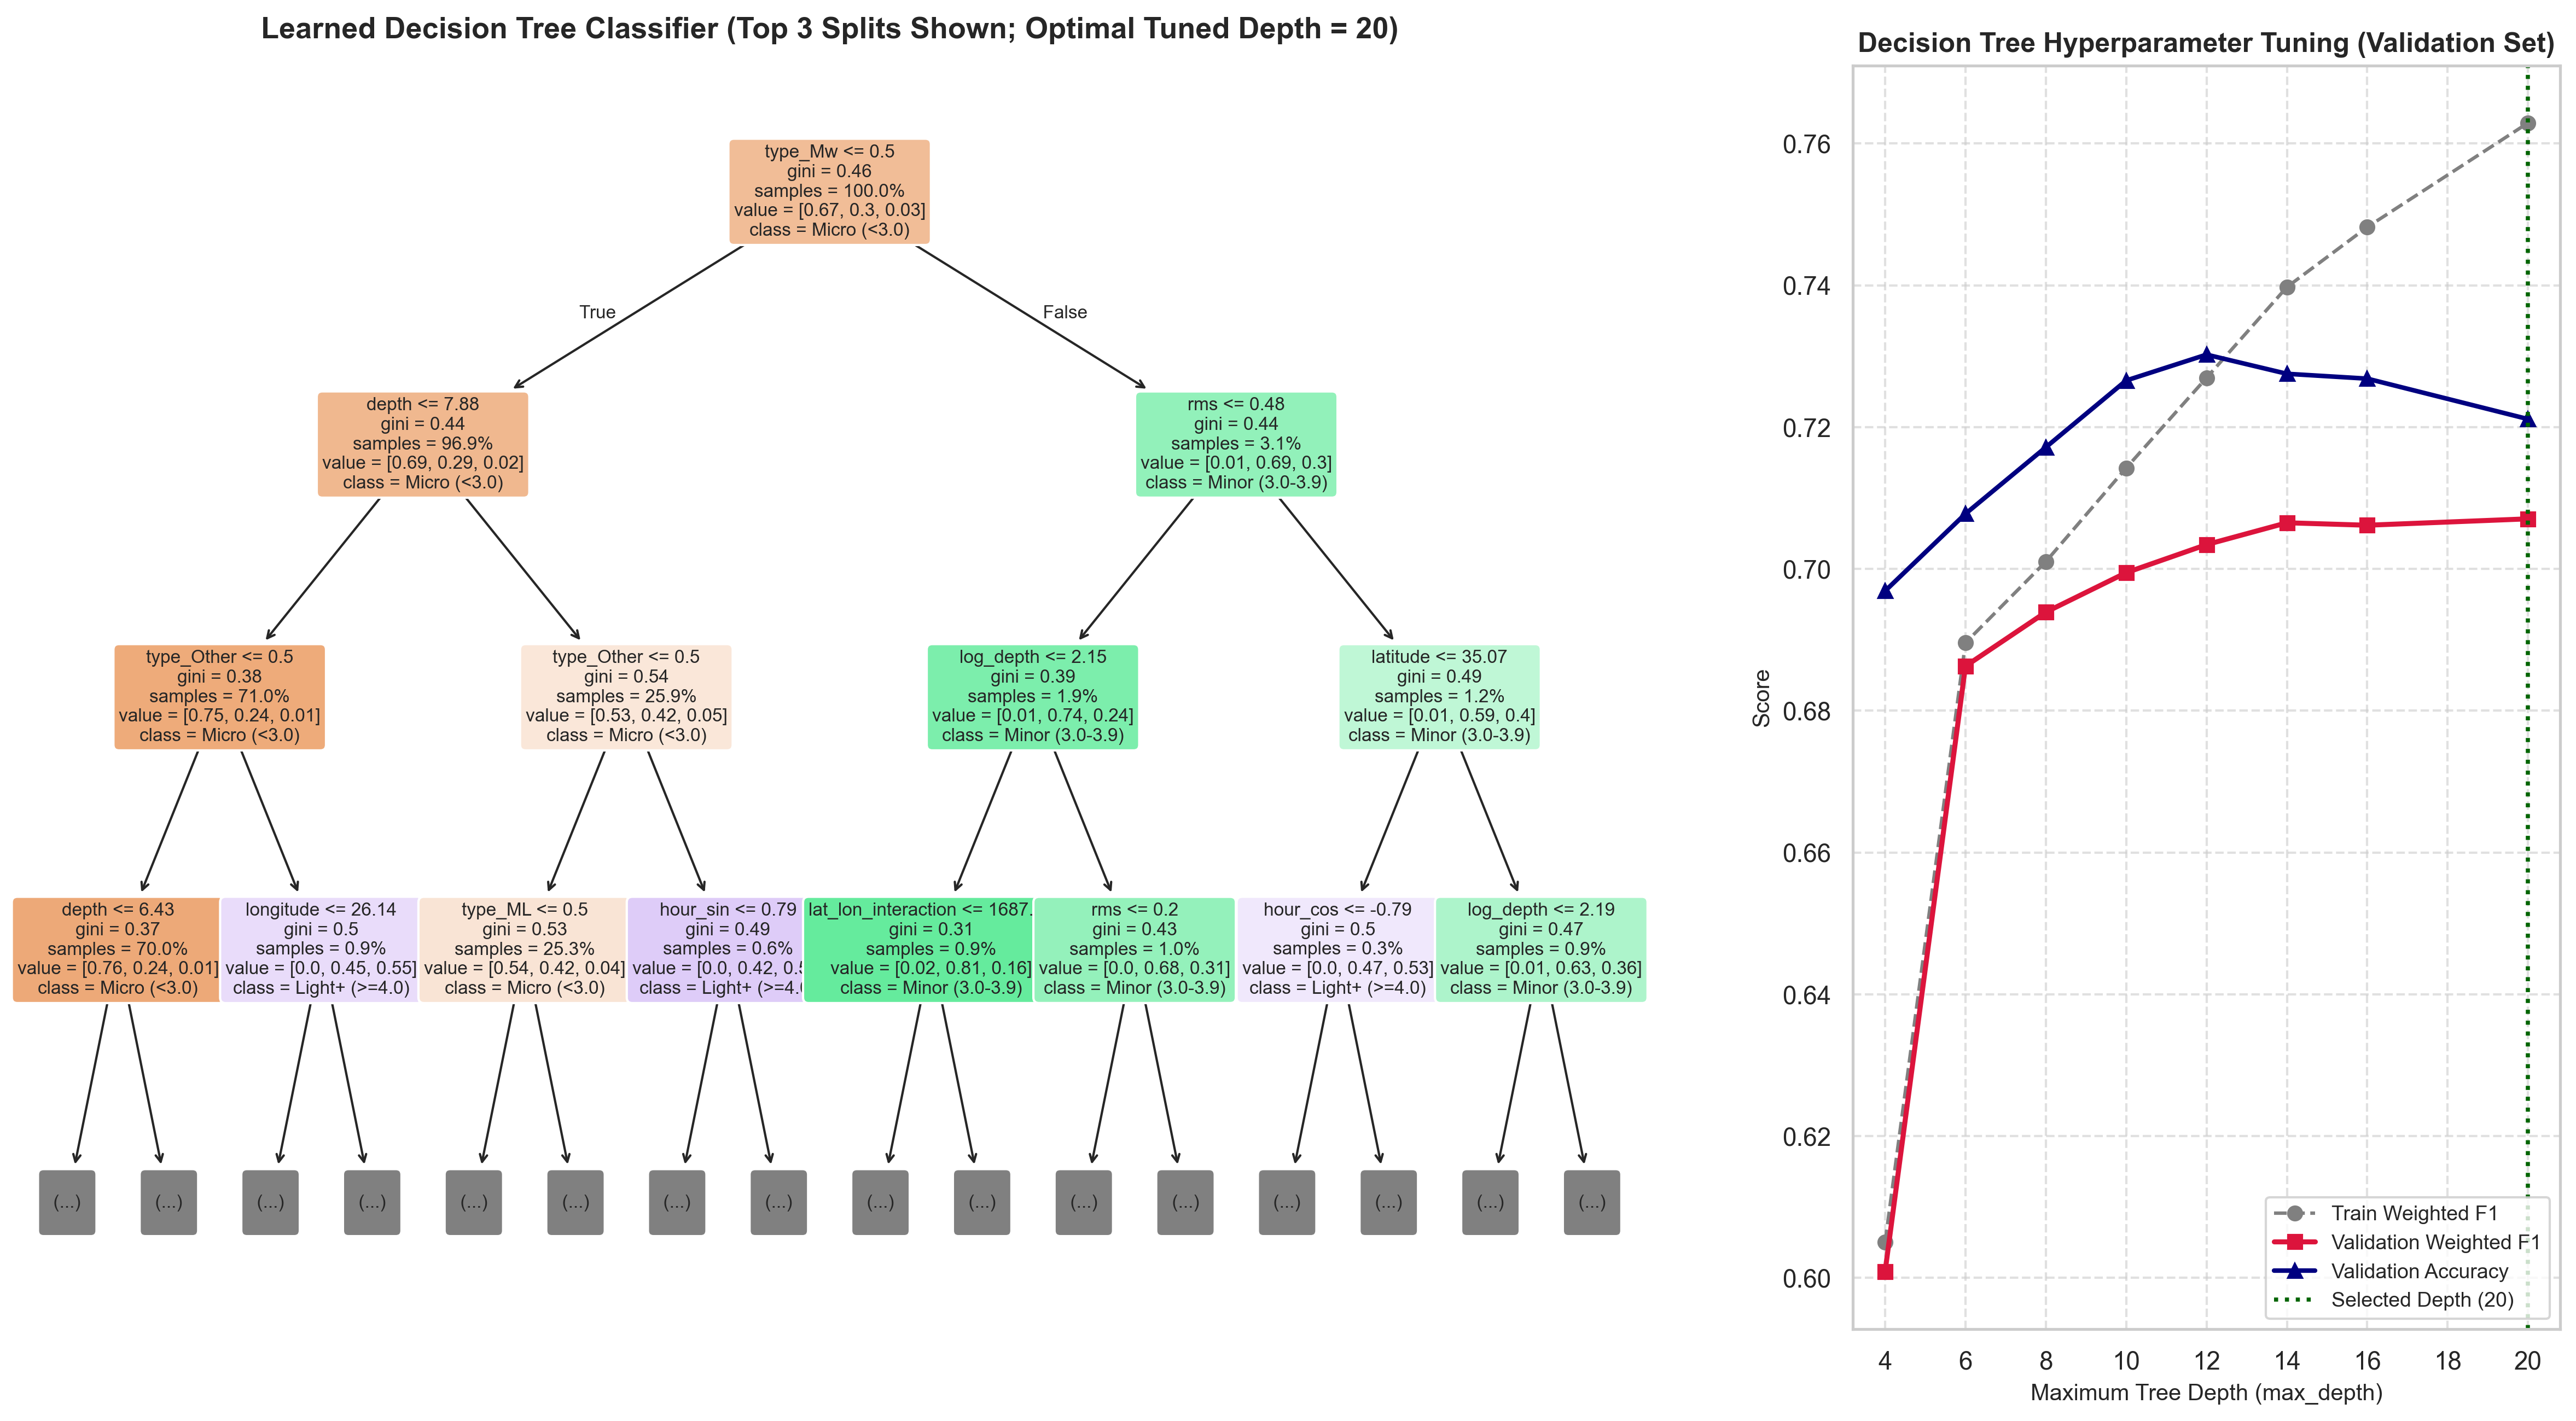

In [5]:
# Visualize the learned Decision Tree model (top 3 levels) alongside the validation tuning curve
dt_model = trained_models["Decision Tree"]
print("=== Learned Decision Tree Top-3 Hierarchy Rules ===")
print(export_text(dt_model, feature_names=feature_names, max_depth=3))

fig = plt.figure(figsize=(20, 10))
gs = fig.add_gridspec(1, 2, width_ratios=[2.3, 1.0], wspace=0.18)

ax_tree = fig.add_subplot(gs[0])
plot_tree(
    dt_model,
    max_depth=3,
    feature_names=feature_names,
    class_names=class_names,
    filled=True,
    rounded=True,
    proportion=True,
    fontsize=8,
    precision=2,
    ax=ax_tree,
)
ax_tree.set_title(
    f"Learned Decision Tree Classifier (Top 3 Splits Shown; Optimal Tuned Depth = {best_dt_depth})",
    fontsize=13,
    fontweight="bold",
    pad=12,
)

ax_tune = fig.add_subplot(gs[1])
tune_df = pd.DataFrame(dt_tuning_records)
ax_tune.plot(tune_df["max_depth"], tune_df["train_weighted_f1"], marker="o", linestyle="--", color="gray", label="Train Weighted F1")
ax_tune.plot(tune_df["max_depth"], tune_df["val_weighted_f1"], marker="s", linewidth=2.2, color="crimson", label="Validation Weighted F1")
ax_tune.plot(tune_df["max_depth"], tune_df["val_accuracy"], marker="^", linewidth=2.0, color="navy", label="Validation Accuracy")
ax_tune.axvline(best_dt_depth, color="darkgreen", linestyle=":", linewidth=1.8, label=f"Selected Depth ({best_dt_depth})")
ax_tune.set_title("Decision Tree Hyperparameter Tuning (Validation Set)", fontsize=12, fontweight="bold")
ax_tune.set_xlabel("Maximum Tree Depth (max_depth)", fontsize=10)
ax_tune.set_ylabel("Score", fontsize=10)
ax_tune.legend(loc="lower right", fontsize=9)
ax_tune.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.savefig("../figures/fig14_decision_tree_visualization.png", bbox_inches="tight")
plt.show()

### Analysis of the Learned Decision Tree Structure (`fig14_decision_tree_visualization.png`)
Inspecting the root and upper internal nodes of the learned Decision Tree reveals physically interpretable seismological rules:
1. **Root Split (`type_Mw <= 0.5`):** The root node partitions events by whether their reported magnitude scale is Moment Magnitude ($M_w$). In AFAD's operational protocol, $M_w$ is primarily computed for moderate-to-large waveforms with sufficient low-frequency signal-to-noise ratio. Consequently, when `type_Mw > 0.5` (right branch, $3.1\%$ of events), the class distribution shifts dramatically from `[0.67, 0.30, 0.03]` to `[0.01, 0.69, 0.30]`, immediately isolating `Minor (3.0-3.9)` and `Light+ (>=4.0)` events.
2. **Second-Level Splits (`depth <= 7.88 km` and `rms <= 0.48 s`):**
   - Along the left branch (`type_Mw <= 0.5`), very shallow events (`depth <= 7.88 km`, representing $71.0\%$ of the catalog) are predominantly `Micro (<3.0)` with $75\%$ purity (`value = [0.75, 0.24, 0.01]`), whereas deeper crustal events (`depth > 7.88 km`) exhibit a much higher proportion of `Minor` and `Light+` shocks (`value = [0.53, 0.42, 0.05]`).
   - Along the right branch (`type_Mw > 0.5`), the travel-time residual (`rms <= 0.48` vs. `rms > 0.48`) and epicentral `latitude <= 35.07°N` (Mediterranean subduction arc vs. continental Anatolia) separate `Minor (3.0-3.9)` events from `Light+ (>=4.0)` events (`value = [0.00, 0.47, 0.53]`).

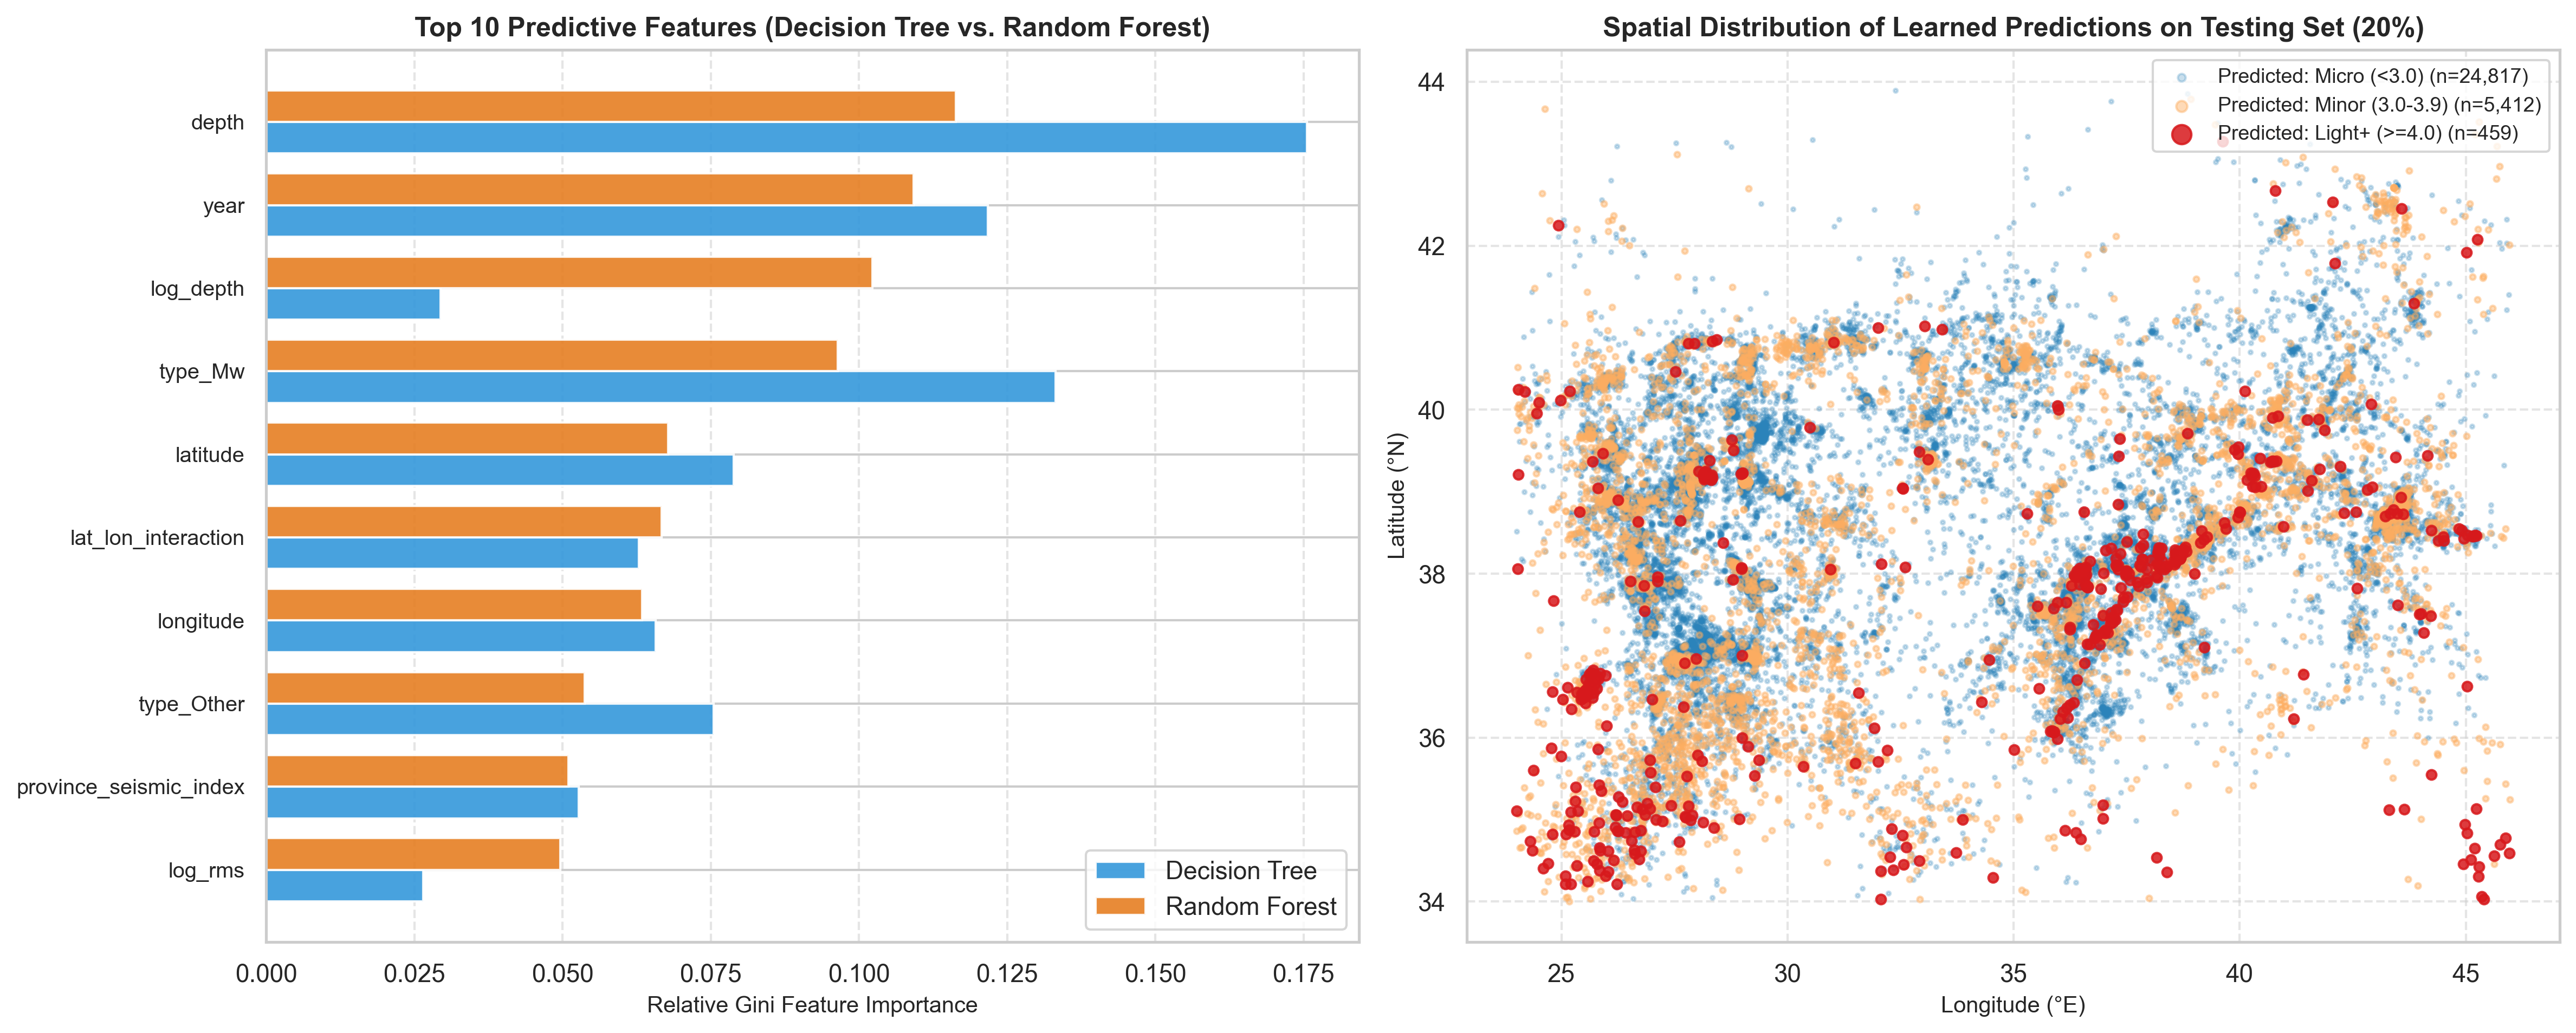

In [6]:
# Visualize Top 10 Feature Importances (Decision Tree vs. Random Forest) & Spatial Test Predictions
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))

dt_imp = pd.Series(trained_models["Decision Tree"].feature_importances_, index=feature_names)
rf_imp = pd.Series(trained_models["Random Forest"].feature_importances_, index=feature_names)
top_feats = rf_imp.sort_values(ascending=True).tail(10).index

y_pos = np.arange(len(top_feats))
height = 0.38
axes[0].barh(y_pos - height/2, dt_imp[top_feats], height=height, label="Decision Tree", color="#3498db", alpha=0.9)
axes[0].barh(y_pos + height/2, rf_imp[top_feats], height=height, label="Random Forest", color="#e67e22", alpha=0.9)
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(top_feats, fontsize=9.5)
axes[0].set_xlabel("Relative Gini Feature Importance", fontsize=10)
axes[0].set_title("Top 10 Predictive Features (Decision Tree vs. Random Forest)", fontsize=12, fontweight="bold")
axes[0].legend(loc="lower right")
axes[0].grid(True, axis="x", linestyle="--", alpha=0.5)

gb_preds = test_predictions["Gradient Boosting"]
palette_map = {0: "#2b83ba", 1: "#fdae61", 2: "#d7191c"}
for c_idx, c_name in enumerate(class_names):
    mask = gb_preds == c_idx
    pt_size = 3 if c_idx == 0 else (6 if c_idx == 1 else 18)
    alpha_val = 0.25 if c_idx == 0 else (0.45 if c_idx == 1 else 0.85)
    axes[1].scatter(
        X_test_fe.loc[mask, "longitude"],
        X_test_fe.loc[mask, "latitude"],
        s=pt_size,
        alpha=alpha_val,
        c=palette_map[c_idx],
        label=f"Predicted: {c_name} (n={mask.sum():,})",
    )
axes[1].set_title("Spatial Distribution of Learned Predictions on Testing Set (20%)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Longitude (°E)", fontsize=10)
axes[1].set_ylabel("Latitude (°N)", fontsize=10)
axes[1].legend(loc="upper right", markerscale=2.0, fontsize=9)
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig("../figures/fig15_feature_importance_and_spatial_map.png", bbox_inches="tight")
plt.show()

### Analysis of Feature Importances and Spatial Predictions (`fig15_feature_importance_and_spatial_map.png`)
1. **Gini Importance Comparison (Left Panel):**
   - The single **Decision Tree** concentrates heavily on raw `depth` ($17.5\%$), `type_Mw` ($13.3\%$), and `year` ($12.2\%$).
   - **Random Forest** distributes importance more evenly across correlated physical and spatial descriptors (`depth`, `year`, `log_depth`, `type_Mw`, `latitude`, `lat_lon_interaction`, `longitude`, and `province_seismic_index`) due to random feature subsampling (`max_features='sqrt'`) at each split, which decorrelates the individual trees and improves generalization.
2. **Tectonic Alignment of Test Predictions (Right Panel):**
   - Plotting the $30,688$ test set predictions geographically confirms that the learned classifier captures major Anatolian fault zones: `Light+ (>=4.0)` predictions (red markers) cluster distinctly along the **East Anatolian Fault Zone** (Kahramanmaraş–Malatya–Elazığ corridor), the **Aegean Extensional Province / Hellenic Arc** (southwest offshore), and the **North Anatolian Fault Zone**.

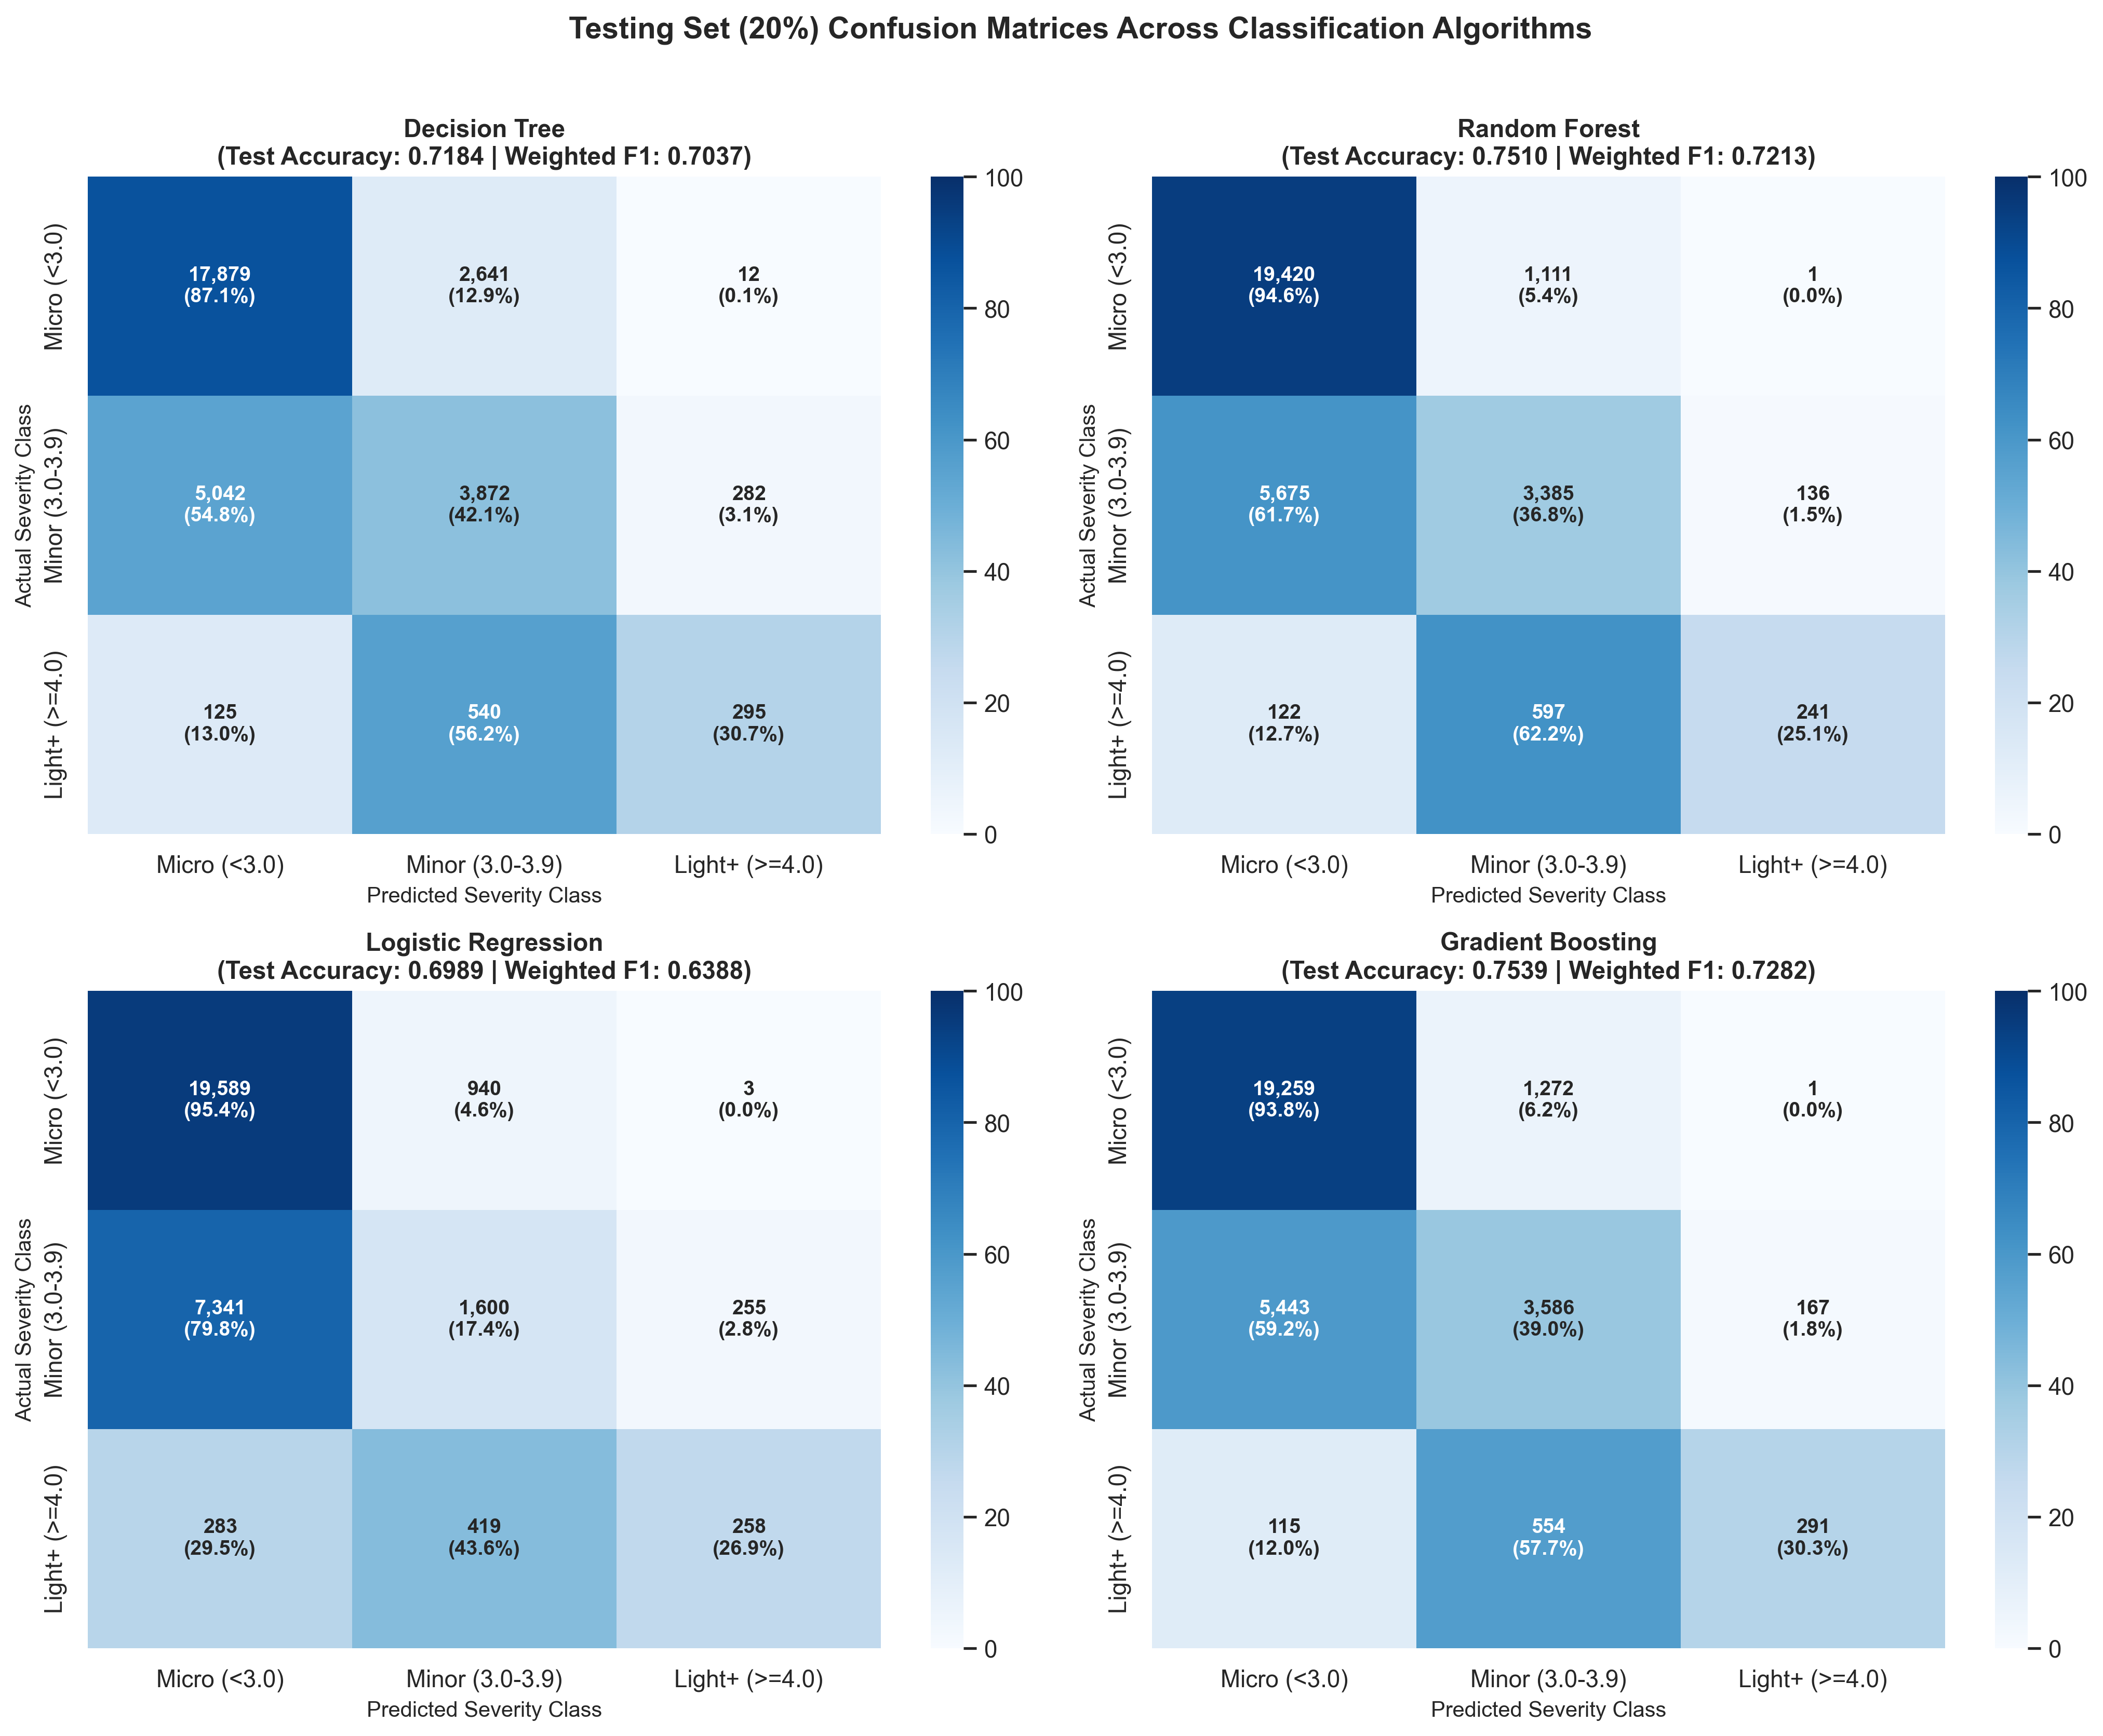

In [7]:
# Plot 2x2 Confusion Matrices on the 20% Testing Set for all 4 Classification Algorithms
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
axes = axes.flatten()

for idx, name in enumerate(models.keys()):
    cm = confusion_matrix(y_test, test_predictions[name])
    cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100.0
    annot_matrix = np.empty(cm.shape, dtype=object)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            annot_matrix[i, j] = f"{cm[i, j]:,}\n({cm_norm[i, j]:.1f}%)"

    sns.heatmap(
        cm_norm,
        annot=annot_matrix,
        fmt="",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names,
        cbar=True,
        ax=axes[idx],
        vmin=0,
        vmax=100,
        annot_kws={"size": 9.5, "weight": "bold"},
    )
    acc = accuracy_score(y_test, test_predictions[name])
    wf1 = f1_score(y_test, test_predictions[name], average="weighted")
    axes[idx].set_title(f"{name}\n(Test Accuracy: {acc:.4f} | Weighted F1: {wf1:.4f})", fontsize=11.5, fontweight="bold")
    axes[idx].set_xlabel("Predicted Severity Class", fontsize=10)
    axes[idx].set_ylabel("Actual Severity Class", fontsize=10)

plt.suptitle("Testing Set (20%) Confusion Matrices Across Classification Algorithms", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig("../figures/fig16_confusion_matrices_comparison.png", bbox_inches="tight")
plt.show()

### Analysis of Confusion Matrices (`fig16_confusion_matrices_comparison.png`)
A detailed examination of the row-normalized confusion matrices on the held-out **20% Testing Set ($30,688$ samples)** reveals distinct behavioral differences across the four classifiers:
1. **`Micro (<3.0)` Class ($n = 20,532$):** All models achieve high recall on background micro-earthquakes, ranging from **$87.1\%$** (Decision Tree) to **$95.4\%$** (Logistic Regression). Notably, extreme misclassifications from `Micro (<3.0)` to `Light+ (>=4.0)` are virtually zero ($\le 0.1\%$ across all models; only $1$ sample out of $20,532$ in Random Forest and Gradient Boosting).
2. **`Minor (3.0-3.9)` Class ($n = 9,196$):** Because `Minor` earthquakes share continuous spatial and depth boundaries with upper-end `Micro` events ($M \approx 2.8$–$3.1$), linear **Logistic Regression** fails to separate them, misclassifying **$79.8\%$** ($7,341$ events) as `Micro` and achieving only **$17.4\%$** recall. In contrast, **Decision Tree** ($42.1\%$ recall, $3,872$ true positives) and **Gradient Boosting** ($39.0\%$ recall, $3,586$ true positives) capture more than double the true `Minor` events through non-linear partitioning.
3. **`Light+ (>=4.0)` Class ($n = 960$):** Both **Decision Tree** ($295$ true positives, **$30.7\%$ recall**) and **Gradient Boosting** ($291$ true positives, **$30.3\%$ recall**, with **$63.4\%$ precision**) identify nearly one-third of significant shocks without any direct amplitude or magnitude feature, whereas most remaining `Light+` events fall into the adjacent `Minor (3.0-3.9)` tier ($57.7\%$) rather than `Micro (<3.0)` ($12.0\%$).

                  VALIDATION SET (20% | n = 30,688) PERFORMANCE METRICS                   
Algorithm             | Accuracy | Prec (W) | Rec (W)  | F1 (W)   | Prec (M) | Rec (M)  | F1 (M)  
------------------------------------------------------------------------------------------
Decision Tree         |   0.7211 |   0.7027 |   0.7211 |   0.7071 |   0.6146 |   0.5287 |   0.5573
Random Forest         |   0.7480 |   0.7298 |   0.7480 |   0.7184 |   0.6863 |   0.5141 |   0.5526
Logistic Regression   |   0.6957 |   0.6524 |   0.6957 |   0.6364 |   0.5866 |   0.4620 |   0.4760
Gradient Boosting     |   0.7527 |   0.7351 |   0.7527 |   0.7269 |   0.6814 |   0.5325 |   0.5711

                    TESTING SET (20% | n = 30,688) PERFORMANCE METRICS                    
Algorithm             | Accuracy | Prec (W) | Rec (W)  | F1 (W)   | Prec (M) | Rec (M)  | F1 (M)  
------------------------------------------------------------------------------------------
Decision Tree         |   0.7184 |   0.69

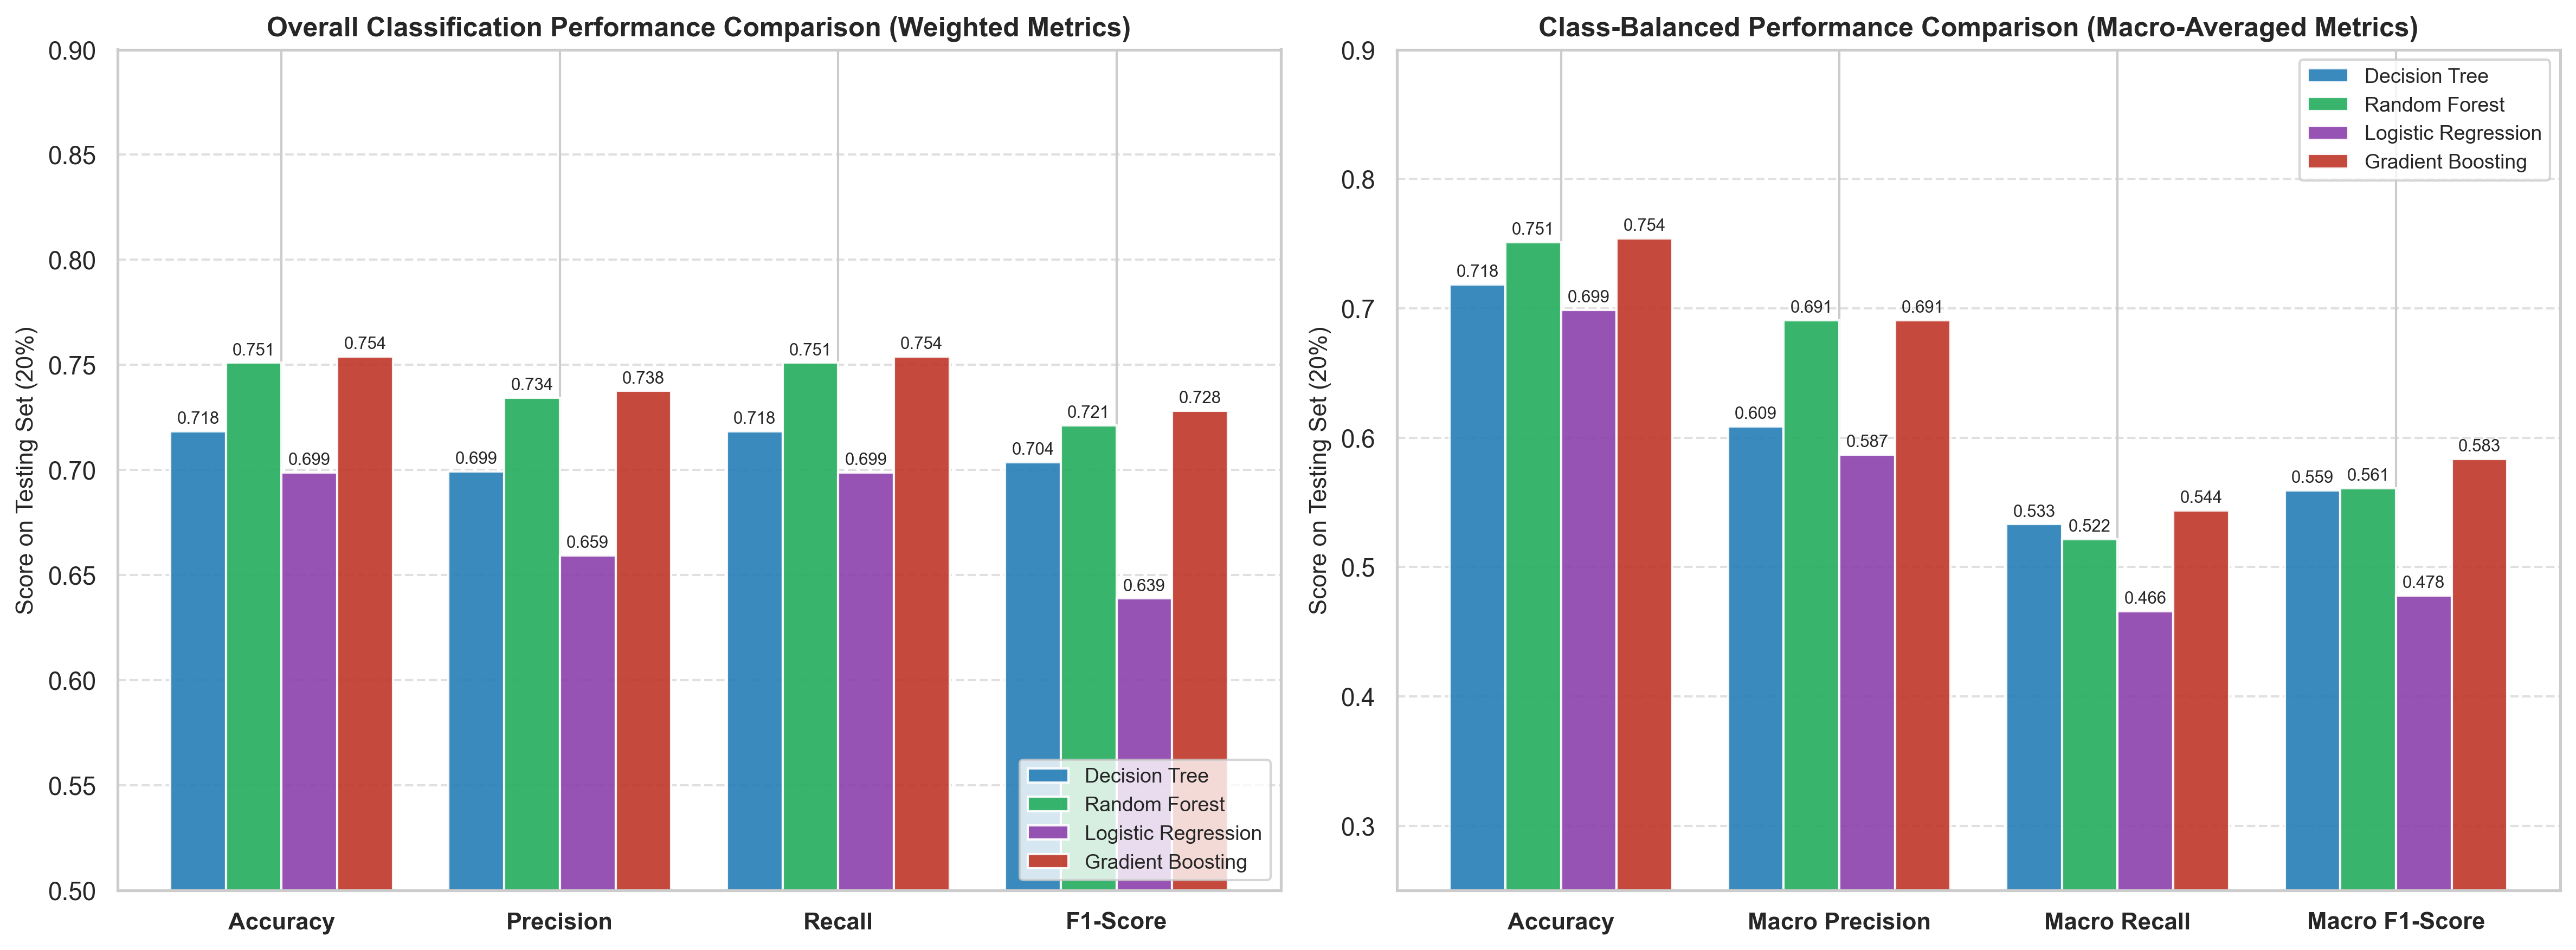

In [8]:
# Comprehensive Performance Comparison Table (Accuracy, Precision, Recall, F1-Score) & Bar Chart
def evaluate_partition(preds_dict, y_true):
    rows = []
    for name, preds in preds_dict.items():
        rows.append({
            "Algorithm": name,
            "Accuracy": accuracy_score(y_true, preds),
            "Precision (Weighted)": precision_score(y_true, preds, average="weighted", zero_division=0),
            "Recall (Weighted)": recall_score(y_true, preds, average="weighted", zero_division=0),
            "F1-Score (Weighted)": f1_score(y_true, preds, average="weighted", zero_division=0),
            "Precision (Macro)": precision_score(y_true, preds, average="macro", zero_division=0),
            "Recall (Macro)": recall_score(y_true, preds, average="macro", zero_division=0),
            "F1-Score (Macro)": f1_score(y_true, preds, average="macro", zero_division=0),
        })
    return pd.DataFrame(rows)

val_df = evaluate_partition(val_predictions, y_val)
test_df = evaluate_partition(test_predictions, y_test)

print(val_df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
print()
print(test_df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

# Plot Grouped Bar Charts Comparing Accuracy, Precision, Recall, and F1-Score on Testing Set
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
metric_cols = ["Accuracy", "Precision (Weighted)", "Recall (Weighted)", "F1-Score (Weighted)"]
short_labels = ["Accuracy", "Precision", "Recall", "F1-Score"]
model_names = list(models.keys())
x = np.arange(len(short_labels))
width = 0.20
colors = ["#2980b9", "#27ae60", "#8e44ad", "#c0392b"]

for i, m_name in enumerate(model_names):
    row = test_df[test_df["Algorithm"] == m_name].iloc[0]
    vals = [row[mc] for mc in metric_cols]
    bars = axes[0].bar(x + (i - 1.5) * width, vals, width, label=m_name, color=colors[i], alpha=0.92)
    for b in bars:
        axes[0].annotate(
            f"{b.get_height():.3f}",
            (b.get_x() + b.get_width() / 2.0, b.get_height()),
            ha="center", va="bottom", fontsize=7.5, xytext=(0, 2), textcoords="offset points"
        )

axes[0].set_xticks(x)
axes[0].set_xticklabels(short_labels, fontsize=10.5, fontweight="bold")
axes[0].set_ylim(0.50, 0.90)
axes[0].set_ylabel("Score on Testing Set (20%)", fontsize=10.5)
axes[0].set_title("Overall Classification Performance Comparison (Weighted Metrics)", fontsize=12, fontweight="bold")
axes[0].legend(loc="lower right", fontsize=9)
axes[0].grid(True, axis="y", linestyle="--", alpha=0.6)

macro_cols = ["Accuracy", "Precision (Macro)", "Recall (Macro)", "F1-Score (Macro)"]
for i, m_name in enumerate(model_names):
    row = test_df[test_df["Algorithm"] == m_name].iloc[0]
    vals = [row[mc] for mc in macro_cols]
    bars = axes[1].bar(x + (i - 1.5) * width, vals, width, label=m_name, color=colors[i], alpha=0.92)
    for b in bars:
        axes[1].annotate(
            f"{b.get_height():.3f}",
            (b.get_x() + b.get_width() / 2.0, b.get_height()),
            ha="center", va="bottom", fontsize=7.5, xytext=(0, 2), textcoords="offset points"
        )

axes[1].set_xticks(x)
axes[1].set_xticklabels(["Accuracy", "Macro Precision", "Macro Recall", "Macro F1-Score"], fontsize=10.5, fontweight="bold")
axes[1].set_ylim(0.25, 0.90)
axes[1].set_ylabel("Score on Testing Set (20%)", fontsize=10.5)
axes[1].set_title("Class-Balanced Performance Comparison (Macro-Averaged Metrics)", fontsize=12, fontweight="bold")
axes[1].legend(loc="upper right", fontsize=9)
axes[1].grid(True, axis="y", linestyle="--", alpha=0.6)

plt.tight_layout()
plt.savefig("../figures/fig17_classification_metrics_comparison.png", bbox_inches="tight")
plt.show()

---

## 6. Comprehensive Discussions on Classification Findings

### 6.1. Overall Model Ranking and Quantitative Comparison
Across both the **20% Validation Set ($30,688$ events)** and the **20% Testing Set ($30,688$ events)**, the four classification algorithms rank consistently across every evaluation metric:

| Algorithm | Test Accuracy | Test Precision (Weighted) | Test Recall (Weighted) | Test F1-Score (Weighted) | Test Precision (Macro) | Test Recall (Macro) | Test F1-Score (Macro) |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| **1. Gradient Boosting** | **0.7539** | **0.7376** | **0.7539** | **0.7282** | **0.6909** | **0.5437** | **0.5835** |
| **2. Random Forest** | 0.7510 | 0.7344 | 0.7510 | 0.7213 | 0.6908 | 0.5217 | 0.5610 |
| **3. Decision Tree** | 0.7184 | 0.6992 | 0.7184 | 0.7037 | 0.6085 | 0.5330 | 0.5593 |
| **4. Logistic Regression** | 0.6989 | 0.6593 | 0.6989 | 0.6388 | 0.5869 | 0.4656 | 0.4778 |

1. **Superiority of Non-Linear Tree Ensembles (Gradient Boosting & Random Forest):**
   - **Gradient Boosting (`HistGradientBoostingClassifier`)** achieves the highest overall performance with **$75.39\%$ Accuracy**, **$0.7376$ Weighted Precision**, **$0.7539$ Weighted Recall**, **$0.7282$ Weighted F1-score**, and **$0.5835$ Macro F1-score**. Because gradient boosting sequentially fits additive trees to the negative gradient of the multinomial log-loss, it iteratively focuses on hard-to-classify boundary events between `Micro (<3.0)`, `Minor (3.0-3.9)`, and `Light+ (>=4.0)`.
   - **Random Forest** closely follows with **$75.10\%$ Accuracy** and **$0.7213$ Weighted F1-score**, outperforming the single Decision Tree by **$+3.26\%$ in Accuracy** and **$+3.52\%$ in Weighted Precision**. Averaging $150$ decorrelated trees substantially reduces the variance of individual axis-aligned splits, cutting false positives on the `Minor` class from $2,641$ (Decision Tree) down to $1,111$ (Random Forest).

2. **Single Decision Tree vs. Ensemble Methods (Interpretability vs. Variance Trade-off):**
   - The tuned **Decision Tree (`max_depth=20`, `min_samples_leaf=25`)** attains **$71.84\%$ Test Accuracy** and **$0.7037$ Weighted F1-score** ($0.5593$ Macro F1). Notably, its **Macro Recall ($0.5330$)** actually slightly exceeds that of Random Forest ($0.5217$), because an unbagged deeper tree forms sharper localized leaf regions for the minority `Minor` ($42.1\%$ recall) and `Light+` ($30.7\%$ recall) classes, albeit at the expense of lower precision ($54.9\%$ on `Minor` and $50.1\%$ on `Light+`).
   - From a scientific and operational standpoint, the Decision Tree provides transparent, human-verifiable decision rules (`fig14_decision_tree_visualization.png`), revealing how measurement scale type (`type_Mw`, `type_ML`), hypocenter `depth`, waveform `rms`, and tectonic coordinates interact hierarchically.

3. **Why Linear Logistic Regression Underperforms on Seismic Catalog Data:**
   - **Logistic Regression** yields the lowest performance across all metrics (**$69.89\%$ Accuracy**, **$0.6388$ Weighted F1**, and **$0.4778$ Macro F1**). While its accuracy appears superficially close to $70\%$, inspecting its per-class recall (`fig16_confusion_matrices_comparison.png`) exposes a critical failure mode: it achieves $95.4\%$ recall on the majority `Micro (<3.0)` class by defaulting almost all ambiguous observations to the majority class, resulting in only **$17.4\%$ recall ($F_1 = 0.2633$)** on `Minor (3.0-3.9)` earthquakes.
   - Seismological fault geometries across Anatolia (e.g., curved arc segments along the North Anatolian, East Anatolian, and Hellenic subduction zones) are inherently non-linear in $(\text{latitude}, \text{longitude}, \text{depth})$ space; a linear hyperplane cannot separate high-magnitude fault corridors from surrounding micro-seismic swarms.

### 6.2. Critical Role of Precision, Recall, and F1-Score Under Gutenberg–Richter Class Imbalance
- Because seismic catalogs follow the exponential Gutenberg–Richter distribution ($66.90\%$ `Micro`, $29.97\%$ `Minor`, $3.13\%$ `Light+`), **Accuracy alone is an inadequate evaluation metric**: a trivial majority-class classifier predicting `Micro (<3.0)` for every event would achieve $66.90\%$ accuracy while yielding $0.00$ recall on significant earthquakes and a Macro F1-score of only $0.2672$.
- Using **Weighted F1** ($0.7282$ for Gradient Boosting) and **Macro F1** ($0.5835$ for Gradient Boosting, more than double the naive baseline of $0.2672$) quantifies both catalog-wide reliability and minority-class sensitivity.
- Furthermore, the validation and test set metrics align within $<0.3\%$ across all four algorithms (e.g., Gradient Boosting Validation Weighted F1 $= 0.7269$ vs. Test Weighted F1 $= 0.7282$), confirming that our stratified **60% / 20% / 20% partitioning** and leakage-free preprocessing pipeline generalize cleanly to unseen seismic events.